In [81]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

from sklearn.tree import DecisionTreeRegressor , plot_tree
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

In [82]:
df = pd.read_csv('autompg.csv')
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [83]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    str    
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    str    
dtypes: float64(3), int64(4), str(2)
memory usage: 35.3 KB


In [84]:
print((df == '?').sum())

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64


In [85]:
df['horsepower'] = df['horsepower'].replace('?', None).astype(float)

In [86]:
print(df['horsepower'].isnull().sum())

6


In [87]:
mean_power = df['horsepower'].mean()
print(mean_power)

df['horsepower'] = df['horsepower'].fillna(mean_power)
print(df['horsepower'].isnull().sum())


104.46938775510205
0


In [88]:
car_list = ['ford', 'chev', 'amc', 'buick', 'plym', 'mazda', 'toy', 'mer', 'vol']
sum=0
for name in car_list:
    list_car = [x for x in df['car name'].iloc[:100] if name in x]
    sum+=len(list_car)
    print(f"{name.upper()} : {list_car}")

print(sum)

FORD : ['ford torino', 'ford galaxie 500', 'ford maverick', 'ford f250', 'ford pinto', 'ford torino 500', 'ford galaxie 500', 'ford country squire (sw)', 'ford mustang', 'ford pinto runabout', 'ford galaxie 500', 'ford gran torino (sw)', 'ford pinto (sw)', 'ford gran torino', 'ford ltd']
CHEV : ['chevrolet chevelle malibu', 'chevrolet impala', 'chevrolet monte carlo', 'chevy c20', 'chevrolet vega 2300', 'chevrolet chevelle malibu', 'chevrolet impala', 'chevrolet vega (sw)', 'chevrolet vega', 'chevrolet impala', 'chevrolet chevelle concours (sw)', 'chevrolet malibu', 'chevrolet caprice classic', 'chevrolet nova custom']
AMC : ['amc rebel sst', 'amc ambassador dpl', 'amc hornet', 'amc gremlin', 'amc gremlin', 'amc matador', 'amc hornet sportabout (sw)', 'amc ambassador sst', 'amc matador (sw)', 'amc matador', 'amc ambassador brougham', 'amc hornet']
BUICK : ['buick skylark 320', 'buick estate wagon (sw)', 'buick lesabre custom', 'buick century 350', 'buick electra 225 custom']
PLYM : ['p

In [89]:
X = df.drop(['mpg', 'car name'], axis=1)
y=df['mpg']

In [90]:
X.head()

,cylinders,displacement,horsepower,weight,acceleration,model year,origin
0,8,307.0,130.0,3504,12.0,70,1
1,8,350.0,165.0,3693,11.5,70,1
2,8,318.0,150.0,3436,11.0,70,1
3,8,304.0,150.0,3433,12.0,70,1
4,8,302.0,140.0,3449,10.5,70,1


In [91]:
y.head()

0    18.0
1    15.0
2    18.0
3    16.0
4    17.0
Name: mpg, dtype: float64

In [92]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

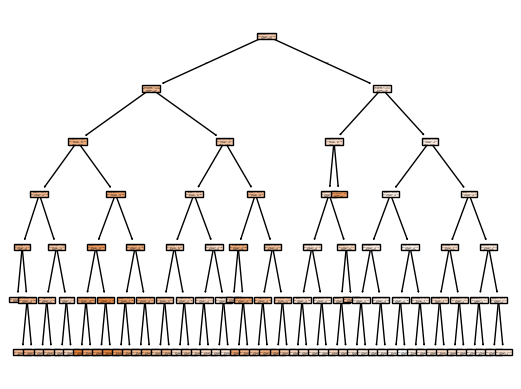

In [93]:
tree_regressor = DecisionTreeRegressor(random_state=42, max_depth=6)
tree_regressor.fit(X_train, y_train)

tree_plot = plot_tree(tree_regressor, feature_names=X_train.columns, filled=True)
plt.show()

In [94]:
tree_pred = tree_regressor.predict(X_test)

print(f"R2 {r2_score(y_test, tree_pred)}")
print(f"MAE {mean_absolute_error(y_test, tree_pred)}")

R2 0.8219495677915192
MAE 2.0525222422859892


In [95]:
normalized = StandardScaler()
X_train_scaled = normalized.fit_transform(X_train)
X_test_scaled = normalized.transform(X_test)

In [96]:
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)
y_pred = linear_model.predict(X_test_scaled)
print("R² Score:", linear_model.score(X_test_scaled, y_test))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))

R² Score: 0.8475731044779437
Mean Absolute Error: 2.2533884059317537
